# 3.7 Métricas

> Borrador de la sección 3.7 (Jose). Se integra en `model_development.ipynb`.

**Para qué se usa el modelo:** una veeduría u oficina de control interno no puede revisar todos los contratos; revisa una lista corta. Lo que importa es **ordenar bien** y que los primeros de la lista sean de verdad contratos que terminan prorrogados.

| Métrica | Por qué |
|---|---|
| **PR-AUC** (principal) | resume la precisión en todos los cortes de la lista; con 25 % de positivos el ROC-AUC puede verse bien aunque los primeros puestos estén llenos de falsos positivos |
| **Precisión y recall en el top 1, 5 y 10 %** | es la decisión real: "si reviso el 5 % de mayor riesgo, ¿qué fracción estaba bien elegida y qué fracción de las prórrogas capturé?" |
| **ROC-AUC** | capacidad de ordenar, independiente de la tasa base; sirve para comparar años con tasas distintas |
| **ROC-AUC dentro de entidad** | lo que ve quien vigila una sola entidad: la regla por entidad da 0,5 ahí por construcción |
| **Tasa base** | siempre al lado: un PR-AUC de 0,58 solo se entiende frente a 0,25 |

No se usan exactitud ni F1 con un umbral fijo: el modelo entrega un orden, y la probabilidad cruda queda descalibrada cuando cambia la tasa (train 0,289, test 2024 0,247).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # el borrador vive en notebooks/; el notebook final, en la raiz de final-project/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
from sklearn.metrics import precision_recall_curve
from src import modelo_io

base = pd.read_parquet(BASE_V1)
X = F.construir_features(base)
idx_tr, idx_te = E.split_temporal(base, config.ANIO_TEST)
pipe, meta = modelo_io.cargar_modelo(config.MODELS / "modelo_prorroga_v1.joblib")
y_te = base.loc[idx_te, "y"].to_numpy()
ent_tr, ent_te = base.loc[idx_tr, "nit_entidad"], base.loc[idx_te, "nit_entidad"]
m = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))["m_regla"]
s = {"modelo v1": pipe.predict_proba(X.loc[idx_te])[:, 1],
     "regla por entidad": E.regla_tasa_entidad(ent_tr, base.loc[idx_tr, "y"], ent_te, m)}
print(f"Test 2024: {len(y_te):,} contratos, tasa base {y_te.mean():.3f}")

Test 2024: 88,088 contratos, tasa base 0.247


## Curva precisión-recall y precisión en los primeros k

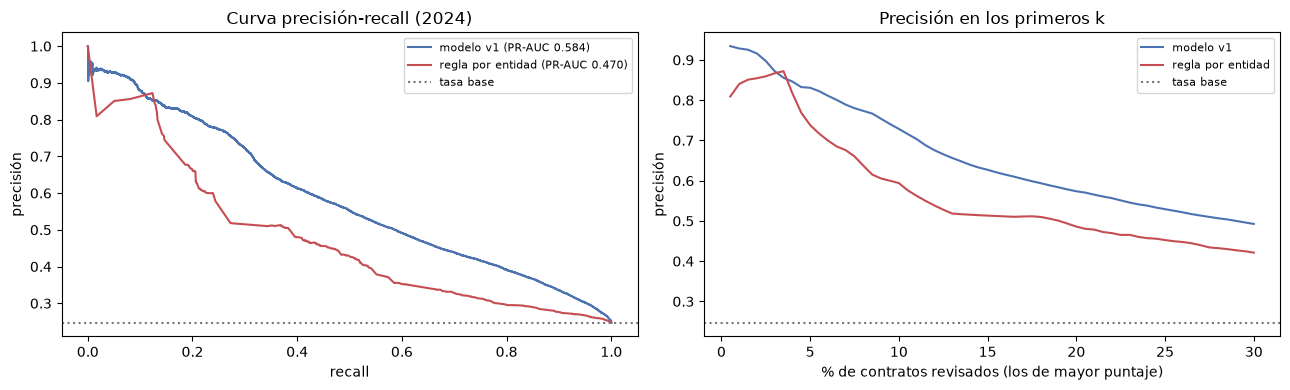

,p@1%,p@5%,p@10%,r@1%,r@5%,r@10%
modelo v1,0.928,0.831,0.729,0.038,0.168,0.295
regla por entidad,0.840,0.738,0.594,0.034,0.149,0.240


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (nombre, sc), color in zip(s.items(), ["#4C72B0", "#C44E52"]):
    p, r, _ = precision_recall_curve(y_te, sc)
    ax[0].plot(r, p, color=color, label=f"{nombre} (PR-AUC {E.metricas(y_te, sc)['pr_auc']:.3f})")
    fr = np.linspace(0.005, 0.3, 60)
    ax[1].plot(fr * 100, [E.metricas(y_te, sc, (f,))[f"p@{f:.0%}"] for f in fr], color=color, label=nombre)
for a in ax:
    a.axhline(y_te.mean(), color="#777", ls=":", label="tasa base")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precisión"); ax[0].set_title("Curva precisión-recall (2024)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("% de contratos revisados (los de mayor puntaje)"); ax[1].set_ylabel("precisión"); ax[1].set_title("Precisión en los primeros k"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame({k: {c: E.metricas(y_te, v)[c] for c in ["p@1%", "p@5%", "p@10%", "r@1%", "r@5%", "r@10%"]} for k, v in s.items()}).T

**Interpretación:** si la veeduría revisa el 5 % de mayor riesgo de 2024 (unos 4.400 contratos), con el modelo el 83 % termina con el plazo ampliado, frente al 74 % con la regla por entidad y al 25 % al azar. En el 10 % la diferencia es mayor (73 % frente a 59 %). Ojo: entre el 2 % y el 4 % las dos curvas casi se tocan; la ventaja del modelo en la parte más alta de la lista es pequeña y crece a partir del 5 %. El recall en esos cortes es bajo (17 % en el top 5 %) porque hay muchos más positivos que contratos revisables: la lista sirve para priorizar, no para encontrar todas las prórrogas.

## ROC-AUC dentro de entidad

In [3]:
r = E.roc_auc_intra_entidad(y_te, s["modelo v1"], ent_te, n_boot=200)
print(f"Modelo v1: por pares {r['pares']:.3f} [{r['pares_ic'][0]:.3f}, {r['pares_ic'][1]:.3f}] | "
      f"promedio por entidad {r['por_entidad']:.3f} [{r['por_entidad_ic'][0]:.3f}, {r['por_entidad_ic'][1]:.3f}]")
print(f"Calculado sobre {r['n_entidades']:,} entidades con ambas clases y {r['n_pares']:,} pares. La regla da 0,500 por construcción.")

Modelo v1: por pares 0.701 [0.604, 0.753] | promedio por entidad 0.703 [0.691, 0.716]
Calculado sobre 1,199 entidades con ambas clases y 11,953,889 pares. La regla da 0,500 por construcción.


**Interpretación:** dentro de una misma entidad, el modelo pone más arriba al contrato que se prorroga en el 70 % de los pares. La regla no puede ordenar nada ahí (todos los contratos de la entidad tienen el mismo puntaje). Es lo que necesita una oficina de control interno que solo vigila su propia entidad.

## Lo que muestra la app: nivel de riesgo y percentil

La app no muestra la probabilidad cruda. Muestra el percentil del puntaje frente a los contratos de 2024 y un nivel (bajo, medio, alto) con los umbrales del `.json` del modelo. Los umbrales son provisionales (percentiles 70 y 90 de 2024) y se acuerdan con Geronimo.

In [4]:
u = meta["umbrales_riesgo"]
sc = s["modelo v1"]
nivel = np.where(sc >= u["alto"], "alto", np.where(sc >= u["medio"], "medio", "bajo"))
t = pd.DataFrame({"y": y_te, "nivel": nivel}).groupby("nivel")["y"].agg(contratos="size", tasa_de_prorroga="mean").reindex(["bajo", "medio", "alto"])
t["% de los contratos"] = t["contratos"] / t["contratos"].sum() * 100
print(f"Umbrales: medio >= {u['medio']:.3f}, alto >= {u['alto']:.3f} ({u['metodo']})")
t

Umbrales: medio >= 0.334, alto >= 0.588 (percentiles 70 y 90 del puntaje en el test 2024 (maduros); provisional, se cuadra con Geronimo)


,contratos,tasa_de_prorroga,% de los contratos
nivel,,,
bajo,61661,0.142,69.999
medio,17618,0.375,20.000
alto,8809,0.729,10.000


**Interpretación:** en 2024 el nivel alto (10 % de los contratos) tiene 73 % de prórrogas, el medio 38 % y el bajo 14 %. Los niveles separan bien el riesgo y son fáciles de explicar a una persona sin formación técnica: "de cada 10 contratos en nivel alto, unos 7 terminaron con el plazo ampliado".